# Translation experiments: all results

The clinical guideline is in English. People will ask questions in **Khmer, Lao or Vietnamese**, and the answer
(a guideline chunk) has to reach them in that language. So translation is needed in two directions:

| direction | used for | experiments below |
|---|---|---|
| **X → English** (Khmer / Lao / Vietnamese → English) | the user's question before retrieval; the few Khmer pages inside the PDF | 1, 2, 5, 6 |
| **English → X** | guideline chunks / answers shown to the user | 3, 4, 7 |

All numbers in this notebook are read from the saved result files in `out/`; nothing is recomputed and no model is
loaded, so it runs on the login node in a few seconds. The scripts that produced each result are named in each section.

**Contents**
1. NLLB-200 600M vs 1.3B (X → English, FLORES + translated queries/documents for retrieval)
2. Does translating the question help Khmer retrieval? (BGE-M3)
3. NLLB-1.3B English → X safety test on 50 guideline chunks (raw vs fixed pipeline)
4. Glossary / do-not-translate test (English → X)
5. Pipeline stage 1: NLLB on the Khmer pages of the PDF
6. LLMs as translation agents, X → English (6 systems)
7. Reverse test, English → X on 100 guideline chunks (NLLB, Qwen3-VL-8B, SEA-LION)
8. **Final comparison: NLLB-1.3B vs Qwen3-VL-8B vs SEA-LION-v4-27B, both directions**9. Small (3–4B) vs mid-size (8B) vs big (20–27B) LLMs, all results


In [1]:
import json, os, re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = os.path.abspath(".")                     # run from the project root (ml/)
OUT = os.path.join(ROOT, "out")
pd.set_option("display.max_colwidth", 120)
load = lambda p: json.load(open(os.path.join(OUT, p), encoding="utf-8"))
show = lambda p, w=1000: display(Image(filename=os.path.join(OUT, p), width=w))
pct = lambda a, b: round(100 * a / b, 1) if b else None
LANG = {"khm": "Khmer", "lao": "Lao", "vie": "Vietnamese"}
# fixed colours per system, the same in every chart of this notebook and in out/*.png
COL = {"NLLB-1.3B": "#257de0", "Qwen3-VL-8B": "#ee7fac", "SEA-LION-v4-27B-IT": "#008a17"}
# section 8 only: NLLB and Qwen3-VL-8B, plus SEA-LION-v4-27B
COL8 = {"NLLB-1.3B": "#257de0", "NLLB-3.3B": "#0b3d91", "Qwen3-VL-8B": "#159a9c",
        "SEA-LION-v4-27B-IT": "#8b0000",
        "Sailor2-20B-Chat": "#5f3dc4"}   # Sailor2-20B: purple (the biggest Sailor2; 3B and 8B are in section 9)   # the small SEA-LION v4 models (Qwen-4B, Gemma-4B, Apertus-8B) are dropped from this comparison

## 1. NLLB-200 600M vs 1.3B (X → English)

**Notebook:** `nllb_full_benchmark.ipynb` · **results:** `out/nllb_benchmark_results.json`, `out/nllb_benchmark.png`

NLLB-200 is Meta's dedicated translation model for 200 languages. Two sizes were compared on three tests:

- **Test 1, FLORES-200 devtest** (1,012 professionally translated sentences per language): Khmer / Lao / Vietnamese → English, scored with BLEU and chrF++ against the English reference.
- **Test 2, translated queries:** 200 medical questions. For Khmer, real Khmer questions from a Khmer medical QA set; for all three languages also a *round trip* (English question → X → English). The English result is used to search 2,000 English answers with BGE-M3; Hit@1 = the right answer is ranked first.
- **Test 3, translated documents:** 50 English documents translated to X and back, then searched among 500.

Decoding: beam 4, sentence by sentence.

BLEU       chrF++      
model       1.3B  600M   1.3B  600M
lang                               
Khmer       31.3  28.6   55.4  53.1
Lao         34.3  32.2   58.1  56.1
Vietnamese  36.6  34.5   59.7  58.1

model                                       1.3B   600M
lang       mode                                        
Khmer      direct X (no back-translation)  0.605  0.590
           real Khmer → EN                 0.695  0.695
           round-trip EN→X→EN              0.695  0.600
Lao        direct X (no back-translation)  0.770  0.735
           round-trip EN→X→EN              0.800  0.760
Vietnamese direct X (no back-translation)  0.825  0.790
           round-trip EN→X→EN              0.850  0.845

Hit@1       chrF++_vs_original        
model       1.3B  600M               1.3B    600M
lang                                             
Khmer       0.84  0.76             57.038  52.627
Lao         0.88  0.88             69.939  65.123
Vietnamese  0.92  0.92             73.893  70.986

baselines: {'test2_EN->EN': {'Hit@1': 0.895, 'Hit@5': 0.97, 'MRR@10': 0.9283611111111111}, 'test2_KM->EN_direct_no_translation': {'Hit@1': 0.65, 'Hit@5': 0.79, 'MRR@10': 0.708720238095238}, 'test3_untranslated_docs': {'Hit@1': 0.94, 'Hit@5': 0.96, 'MRR@10': 0.95}}


,n,EN→X loops,X→EN loops
t2_khm_roundtrip.1.3B,200,28,8
t2_khm_roundtrip.600M,200,45,12
t2_lao_roundtrip.1.3B,200,4,3
t2_lao_roundtrip.600M,200,33,8
t2_vie_roundtrip.1.3B,200,0,0
t2_vie_roundtrip.600M,200,1,0
t3_khm_docs.1.3B,500,108,41
t3_khm_docs.600M,500,134,47
t3_lao_docs.1.3B,500,35,11
t3_lao_docs.600M,500,87,18


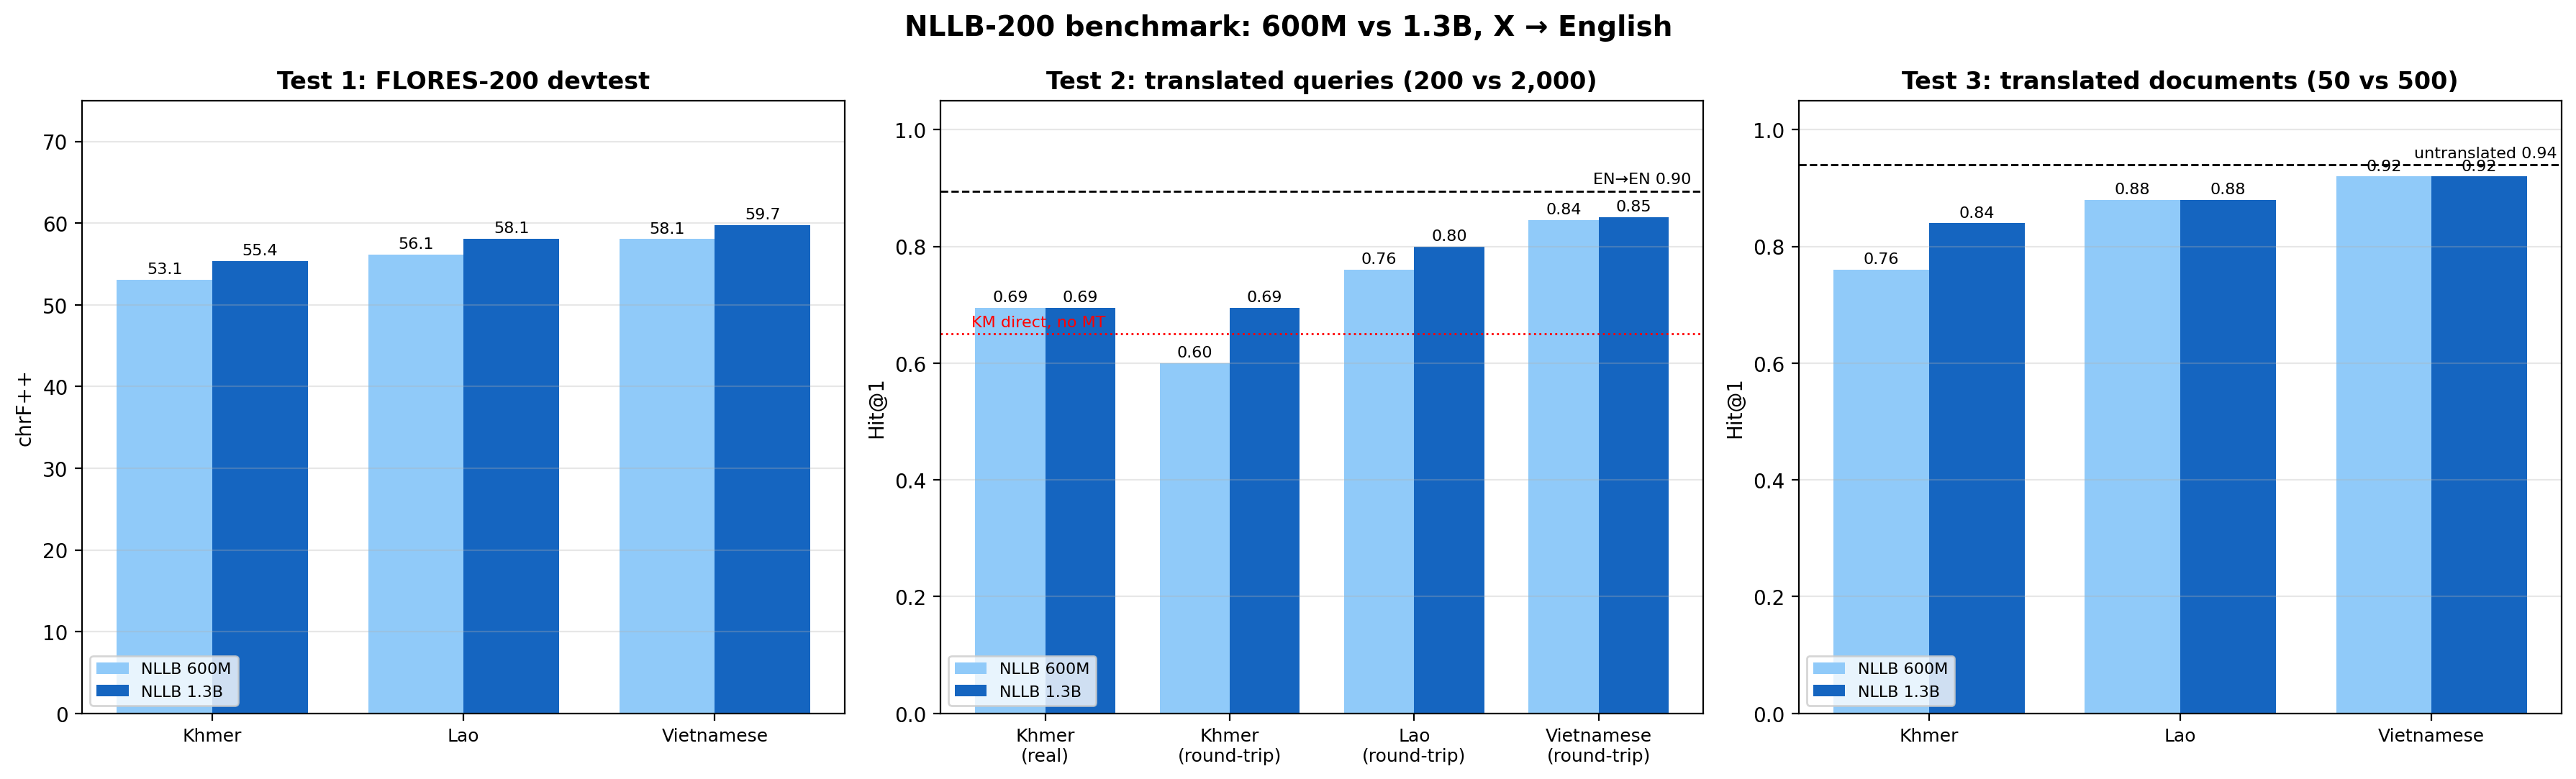

In [2]:
nb = load("nllb_benchmark_results.json")
t1 = pd.DataFrame([r for r in nb["test1_flores"] if r["split"] == "devtest"])
display(t1.pivot(index="lang", columns="model", values=["BLEU", "chrF++"]).round(1))
t2 = pd.DataFrame(nb["test2_queries"]).pivot_table(index=["lang", "mode"], columns="model", values="Hit@1")
display(t2.round(3))
display(pd.DataFrame(nb["test3_documents"]).pivot(index="lang", columns="model", values=["Hit@1", "chrF++_vs_original"]).round(3))
print("baselines:", nb["baselines"])
loops = {k: v for k, v in nb["repetition_loops"]["counts"].items() if v["fwd_EN_to_X_loops"] is not None}
display(pd.DataFrame(loops).T.rename(columns={"fwd_EN_to_X_loops": "EN→X loops", "back_X_to_EN_loops": "X→EN loops"}))
show("nllb_benchmark.png", 1100)

**Result.** 1.3B is better than 600M everywhere (about +2 chrF++ on FLORES, +0.08 Hit@1 on Khmer documents) and loops
less often when translating *into* Khmer and Lao (Khmer documents: 108 vs 134 of 500 outputs repeat themselves).
Vietnamese has almost no loops. **NLLB-1.3B became the default model.** Translating into Khmer is the weak spot: about
1 in 5 Khmer document translations loops.

## 2. Does translating the question help Khmer retrieval?

**Notebook:** `crosslingual_test_part4_nllb.ipynb` · **results:** `out/xling_part4_retrieval.csv`, `out/xling_part4.png`

200 real Khmer medical questions are used to search the English answers with BGE-M3. Four settings: the English
question (upper bound), the Khmer question embedded directly (BGE-M3 is multilingual), and the Khmer question translated
to English by NLLB first, either as a whole or sentence by sentence.

,pipeline,Hit@1,Hit@5,MRR@10,gap recovered (Hit@1)
0,1. EN→EN (baseline),0.895,0.97,0.928,1.000
1,2. KM→EN direct,0.650,0.79,0.709,0.000
2,3a. KM→NLLB(whole)→EN,0.695,0.82,0.747,0.184
3,3b. KM→NLLB(sentences)→EN,0.695,0.86,0.758,0.184


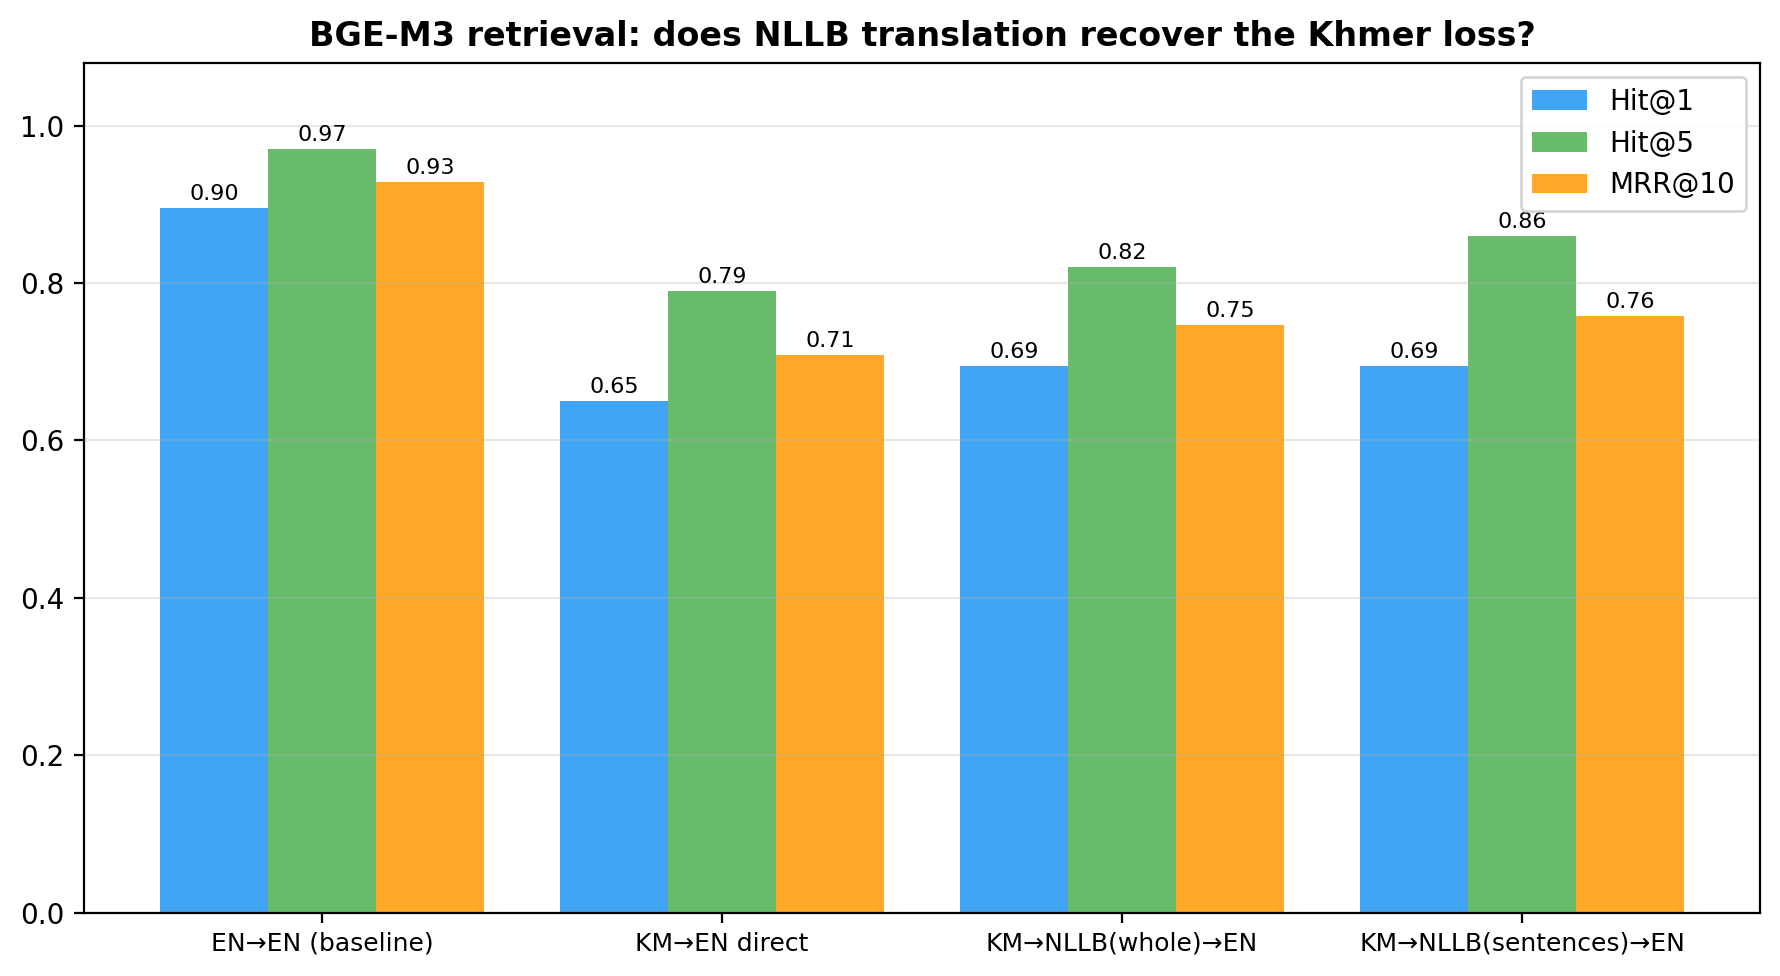

In [3]:
display(pd.read_csv(os.path.join(OUT, "xling_part4_retrieval.csv")).round(3))
show("xling_part4.png", 800)

**Result.** Translating the Khmer question first helps a little (Hit@1 0.65 → 0.69, Hit@5 0.79 → 0.86 when translated
sentence by sentence) but recovers only about a fifth of the gap to the English question (0.90). Translation quality
of the question is therefore a real bottleneck for Khmer, which is why better X → English models are tested in section 6.

## 3. NLLB-1.3B English → X safety test (50 guideline chunks)

**Script:** `mt_safety_test.py` · **results:** `out/mt_safety/report_{raw,fixed}.json`, `out/mt_safety/REPORT.md`

For the other direction there is no human translation of the guideline, so the test checks things that must never
change in a medical translation: **numbers** (locale-aware: Vietnamese/Khmer/Lao write 0,5 for 0.5), **negations**
(a "do not" that disappears is dangerous), **drug names**, **units**, plus a **back-translation** to English compared
with the source (BLEU / chrF++). 50 chunks were picked from the guideline, 10 per category (dosage, negation, ...).

Two variants:
- **raw:** NLLB as is.
- **fixed:** the pre/post-processing now used in the pipeline: en-dash → hyphen (NLLB has no en-dash and `30–35` became `3035`), a better sentence splitter (NLLB silently drops a second sentence), one retry with an n-gram block when the output loops, and repair of decimals that NLLB spaces out (`0, 5`).

In [4]:
def safety(variant):
    rep = load(f"mt_safety/report_{variant}.json")
    rows = {}
    for lk, L in rep["langs"].items():
        c = L["counts"]
        rows[LANG[lk]] = {"numbers kept % (locale)": pct(c["num_locale"], c["num_total"]),
                          "extra numbers": c["num_spurious"],
                          "negation present %": pct(c["neg_present"], c["neg_chunks"]),
                          "drug names Latin %": pct(c["drug_latin"], c["drug_total"]),
                          "units kept %": pct(c["unit_ok"], c["unit_total"]),
                          "BT chrF++": round(L["bt_chrF++"], 1),
                          "all checks pass %": pct(c["chunks_all_ok"], rep["n_chunks"])}
    return pd.DataFrame(rows).T
for v in ("raw", "fixed"):
    display(Markdown(f"**{v}**")); display(safety(v))

**raw**

,numbers kept % (locale),extra numbers,negation present %,drug names Latin %,units kept %,BT chrF++,all checks pass %
Khmer,91.0,14.0,92.0,82.8,95.4,56.4,82.0
Lao,85.4,19.0,92.0,98.3,100.0,68.4,80.0
Vietnamese,84.7,34.0,96.0,100.0,100.0,69.3,80.0


**fixed**

,numbers kept % (locale),extra numbers,negation present %,drug names Latin %,units kept %,BT chrF++,all checks pass %
Khmer,100.0,7.0,92.0,81.0,92.3,59.3,90.0
Lao,100.0,4.0,96.0,98.3,100.0,68.7,98.0
Vietnamese,100.0,22.0,100.0,100.0,100.0,70.2,100.0


**Result.** The fixes matter: chunks passing every check go from 80–82% to 90% (Khmer), 98% (Lao) and 100%
(Vietnamese), and numbers are kept 100% (locale-aware). What is left is mostly Khmer: drug names transliterated into
Khmer script (81% kept in Latin) and units. The back-translations also show clinical terms that get lost
(*intubation* in all three languages, *IM* route in Khmer/Vietnamese), which number checks cannot see.

## 4. Glossary / do-not-translate test (English → X)

**Scripts:** `build_glossary.py`, `glossary_mt.py`, `ocr_glossary.py`, `tess_glossary.py` · **results:** `out/mt_safety/report_{glossary,protect}.json`

Can a medical glossary fix the lost terms? The MOH English–Lao medical glossary was OCR'd (Tesseract, Chandra as a
cross-check; 1,017 entries) and Vietnamese terms were taken from Wikidata. No Khmer glossary could be downloaded.
Glossary terms, drug names and abbreviations were replaced by placeholders (`TERM1`) before NLLB and put back after.

- **glossary:** fixed pipeline + glossary terms + drug names / abbreviations protected.
- **protect:** fixed pipeline + only drug names / abbreviations protected (a do-not-translate list).

drug names Latin %                   BT chrF++                   \
language              Khmer    Lao Vietnamese     Khmer   Lao Vietnamese   
variant                                                                    
fixed                  81.0   98.3      100.0      59.3  68.7       70.2   
glossary              100.0  100.0      100.0      60.0  69.4       70.3   
protect               100.0  100.0      100.0      60.0  68.2       70.8   

         all checks pass %                   
language             Khmer   Lao Vietnamese  
variant                                      
fixed                 90.0  98.0      100.0  
glossary              90.0  98.0      100.0  
protect               90.0  98.0      100.0

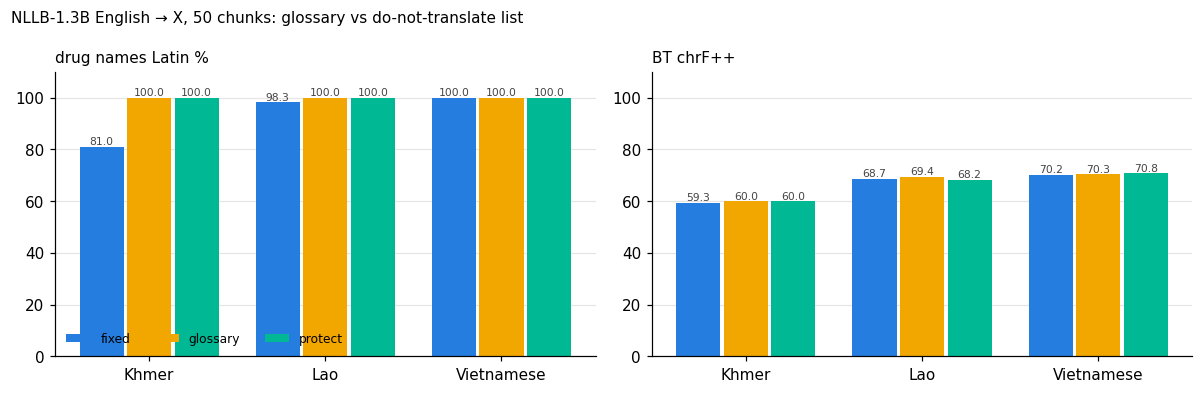

In [5]:
rows = []
for v in ("fixed", "glossary", "protect"):
    for lang, r in safety(v).iterrows():
        rows.append({"variant": v, "language": lang, **r})
g = pd.DataFrame(rows)
display(g.pivot(index="variant", columns="language", values=["drug names Latin %", "BT chrF++", "all checks pass %"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=110)
vcol = {"fixed": "#257de0", "glossary": "#f2a600", "protect": "#00b894"}
for ax, key in zip(axes, ["drug names Latin %", "BT chrF++"]):
    langs = list(LANG.values())
    for j, v in enumerate(vcol):
        vals = [g[(g.variant == v) & (g.language == l)][key].item() for l in langs]
        xs = [i + (j - 1) * 0.27 for i in range(3)]
        b = ax.bar(xs, vals, 0.25, color=vcol[v], label=v, zorder=2)
        ax.bar_label(b, fmt="%.1f", fontsize=7, color="#444")
    ax.set_xticks(range(3)); ax.set_xticklabels(langs); ax.set_title(key, loc="left", fontsize=10)
    ax.set_ylim(0, 110); ax.grid(axis="y", color="#e5e5e5", zorder=0)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=8, ncol=3, loc="lower left")
fig.suptitle("NLLB-1.3B English → X, 50 chunks: glossary vs do-not-translate list", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

**Result.** The glossary adds nothing beyond the do-not-translate list. The glossaries don't contain the terms that
fail (*intubation, infusion, saline, IV/IM, bolus, contraindicated, wean*), and placeholders split noun phrases,
causing new meaning errors ("alternative to DHP CCBs" → "CCBs instead of DHP"). The gain (Khmer drug names 81% → 100%,
about +1.5 BLEU) comes entirely from keeping drug names and abbreviations verbatim.

## 5. Pipeline stage 1: NLLB on the Khmer pages of the PDF

**Code:** `pipeline/translate.py`, `pipeline/extract.py` · **results:** `out/pipeline/stage1_translate/translations.jsonl`, `out/pipeline/pipeline_report.md`

The PDF has Khmer on p1 and p266 (text layer) and p4–6 (scanned; OCR by Chandra). Stage 1 translates these 44
segments with NLLB-1.3B (fixed pipeline). Because there is no reference, each translation is back-translated to Khmer
and compared with the source (chrF, a quality estimate). Stage 2 uses a translation only if chrF ≥ 60 and no number was
lost; otherwise it writes an English placeholder that keeps the numbers.

In [6]:
seg = pd.DataFrame([json.loads(l) for l in open(os.path.join(OUT, "pipeline/stage1_translate/translations.jsonl"), encoding="utf-8")])
seg["used"] = (seg["qe_chrf"] >= 60) & ~seg["flags"].apply(lambda f: bool(f.get("numbers_lost")))   # same rule as stage 2
print(f"{len(seg)} segments, used {seg.used.sum()}, withheld {(~seg.used).sum()}")
display(seg.groupby("page").agg(segments=("seg_id", "count"), used=("used", "sum"), mean_chrF=("qe_chrf", "mean")).round(1))
display(seg[["page", "original", "translation", "qe_chrf"]].sort_values("qe_chrf").head(6))

44 segments, used 18, withheld 26


,segments,used,mean_chrF
page,,,
1,8,2,26.0
4,13,10,70.2
5,9,6,71.2
6,2,0,39.3
266,12,0,14.9


,page,original,translation,qe_chrf
41,266,ពស់ល ឿែ,How do we know that Jehovah's Witnesses are genuine?,2.0
35,266,ពស់ប្ាយកាលប្កហម,"The snake, however, was not a snake.",3.2
40,266,ពស់ល ៀែវនែកធំ,"It is also known as the great horned viper, or big horned viper.",3.8
6,1,សេជ្ជសាស្រសតទូសៅ,"In the meantime, I'm trying to find a way to make it work.",4.1
32,266,ពស់វែករន ៀម,How do we know that Jehovah's Witnesses are genuinely interested in us?,4.4
5,1,ម្គគុសទេសរ៍រាបាលគលីនិរ,"In the first century C.E., the Greek city of Magdala was the capital of the Roman Empire.",4.8


**Result.** NLLB **invents whole sentences** for short Khmer names and for the PDF's broken Khmer encoding. For example,
a Cambodian snake name on p266 became *"How do we know that Jehovah's Witnesses are genuine?"*. The chrF gate catches
these: 26 of the 44 segments are withheld. This was the reason to look for a
stronger X → English model (section 6).

## 6. LLMs as translation agents, X → English

**Script:** `translation_agent.py` · **results:** `out/translation_agent_results.json`, `out/translation_agent_report.md`, `out/translation_agent_bleu.png`

Same test sets as section 1: FLORES-200 devtest (1,012 sentences) Khmer / Lao / Vietnamese → English, plus the 200
real Khmer medical questions (reference: the dataset's English question). NLLB-1.3B outputs are the saved ones from
section 1 (beam 4). Each LLM gets the same system prompt ("You are a medical translator ... keep every number ...
never drop a negation ... keep drug names") and greedy decoding.

LLMs tested: Llama-2-7B-chat, Llama-3.1-8B-Instruct, Gemma-3-4B-it, Qwen3-VL-8B (text only), and
**SEA-LION-v4-27B-IT** (AI Singapore's Gemma-3-27B, further trained on Southeast Asian languages incl. Khmer and Lao).

Scores: BLEU and chrF++ (sacrebleu), **COMET** (Unbabel wmt22-comet-da, a learned metric closer to human judgement),
numbers kept, loops, output not in English, seconds per 100 sentences on one H200.

**Khmer (FLORES)**

,BLEU,chrF++,COMET,numbers_kept_pct,loops,not_english,sec_per_100
model,,,,,,,
NLLB-1.3B,31.30,55.37,0.853,93.3,0,0,NaN
NLLB-3.3B,32.90,56.93,0.864,94.2,1,0,NaN
Llama-2-7B-chat,0.86,18.08,0.483,74.7,289,4,28.25
Llama-3.1-8B-Instruct (extra),18.81,47.04,0.808,95.8,6,15,18.11
Gemma-3-4B-it,20.64,50.02,0.831,96.9,0,1,4.05
Qwen3-VL-8B (text-only),22.21,50.06,0.838,93.3,0,0,5.70
SEA-LION-v4-27B-IT,28.49,56.39,0.864,99.4,0,0,7.12
Qwen-SEA-LION-v4-4B-VL,16.62,43.68,0.795,95.0,0,0,4.08
Gemma-SEA-LION-v4-4B-VL,22.58,51.62,0.841,96.4,0,0,3.17


**Lao (FLORES)**

,BLEU,chrF++,COMET,numbers_kept_pct,loops,not_english,sec_per_100
model,,,,,,,
NLLB-1.3B,34.25,58.10,0.861,95.9,0,0,NaN
NLLB-3.3B,37.25,60.27,0.870,95.0,1,0,NaN
Llama-2-7B-chat,0.76,16.87,0.450,79.9,454,20,28.56
Llama-3.1-8B-Instruct (extra),11.03,35.81,0.680,98.3,5,8,5.41
Gemma-3-4B-it,24.21,51.78,0.830,99.4,0,0,3.80
Qwen3-VL-8B (text-only),26.75,53.25,0.847,98.3,0,0,4.99
SEA-LION-v4-27B-IT,34.25,59.61,0.872,99.7,0,0,8.18
Qwen-SEA-LION-v4-4B-VL,18.95,44.92,0.790,98.1,1,0,4.26
Gemma-SEA-LION-v4-4B-VL,25.96,53.30,0.840,99.2,0,0,2.94


**Vietnamese (FLORES)**

,BLEU,chrF++,COMET,numbers_kept_pct,loops,not_english,sec_per_100
model,,,,,,,
NLLB-1.3B,36.58,59.74,0.867,89.9,0,0,NaN
NLLB-3.3B,38.23,61.31,0.875,90.7,0,0,NaN
Llama-2-7B-chat,23.37,50.43,0.824,93.7,0,0,8.90
Llama-3.1-8B-Instruct (extra),32.87,58.63,0.868,94.2,0,0,2.36
Gemma-3-4B-it,31.07,57.10,0.865,95.0,0,0,3.31
Qwen3-VL-8B (text-only),34.84,59.75,0.877,93.4,0,0,3.06
SEA-LION-v4-27B-IT,35.93,60.72,0.877,96.6,0,0,5.32
Qwen-SEA-LION-v4-4B-VL,32.83,58.04,0.871,93.9,0,0,2.21
Gemma-SEA-LION-v4-4B-VL,31.92,57.78,0.869,95.0,0,0,2.52


**Khmer medical Qs**

,BLEU,chrF++,COMET,numbers_kept_pct,loops,not_english,sec_per_100
model,,,,,,,
NLLB-1.3B,27.77,50.16,0.792,75.1,0,0,NaN
NLLB-3.3B,28.78,49.76,0.799,73.1,1,0,NaN
Llama-2-7B-chat,0.80,18.90,0.541,29.2,70,1,58.52
Llama-3.1-8B-Instruct (extra),22.55,43.11,0.729,93.7,10,14,46.11
Gemma-3-4B-it,29.83,53.09,0.797,98.0,0,0,6.50
Qwen3-VL-8B (text-only),33.89,54.98,0.808,94.1,0,0,13.72
SEA-LION-v4-27B-IT,40.47,60.77,0.827,100.0,1,0,18.48
Qwen-SEA-LION-v4-4B-VL,26.83,49.04,0.783,96.4,0,0,13.68
Gemma-SEA-LION-v4-4B-VL,31.66,54.42,0.804,96.8,0,0,8.66


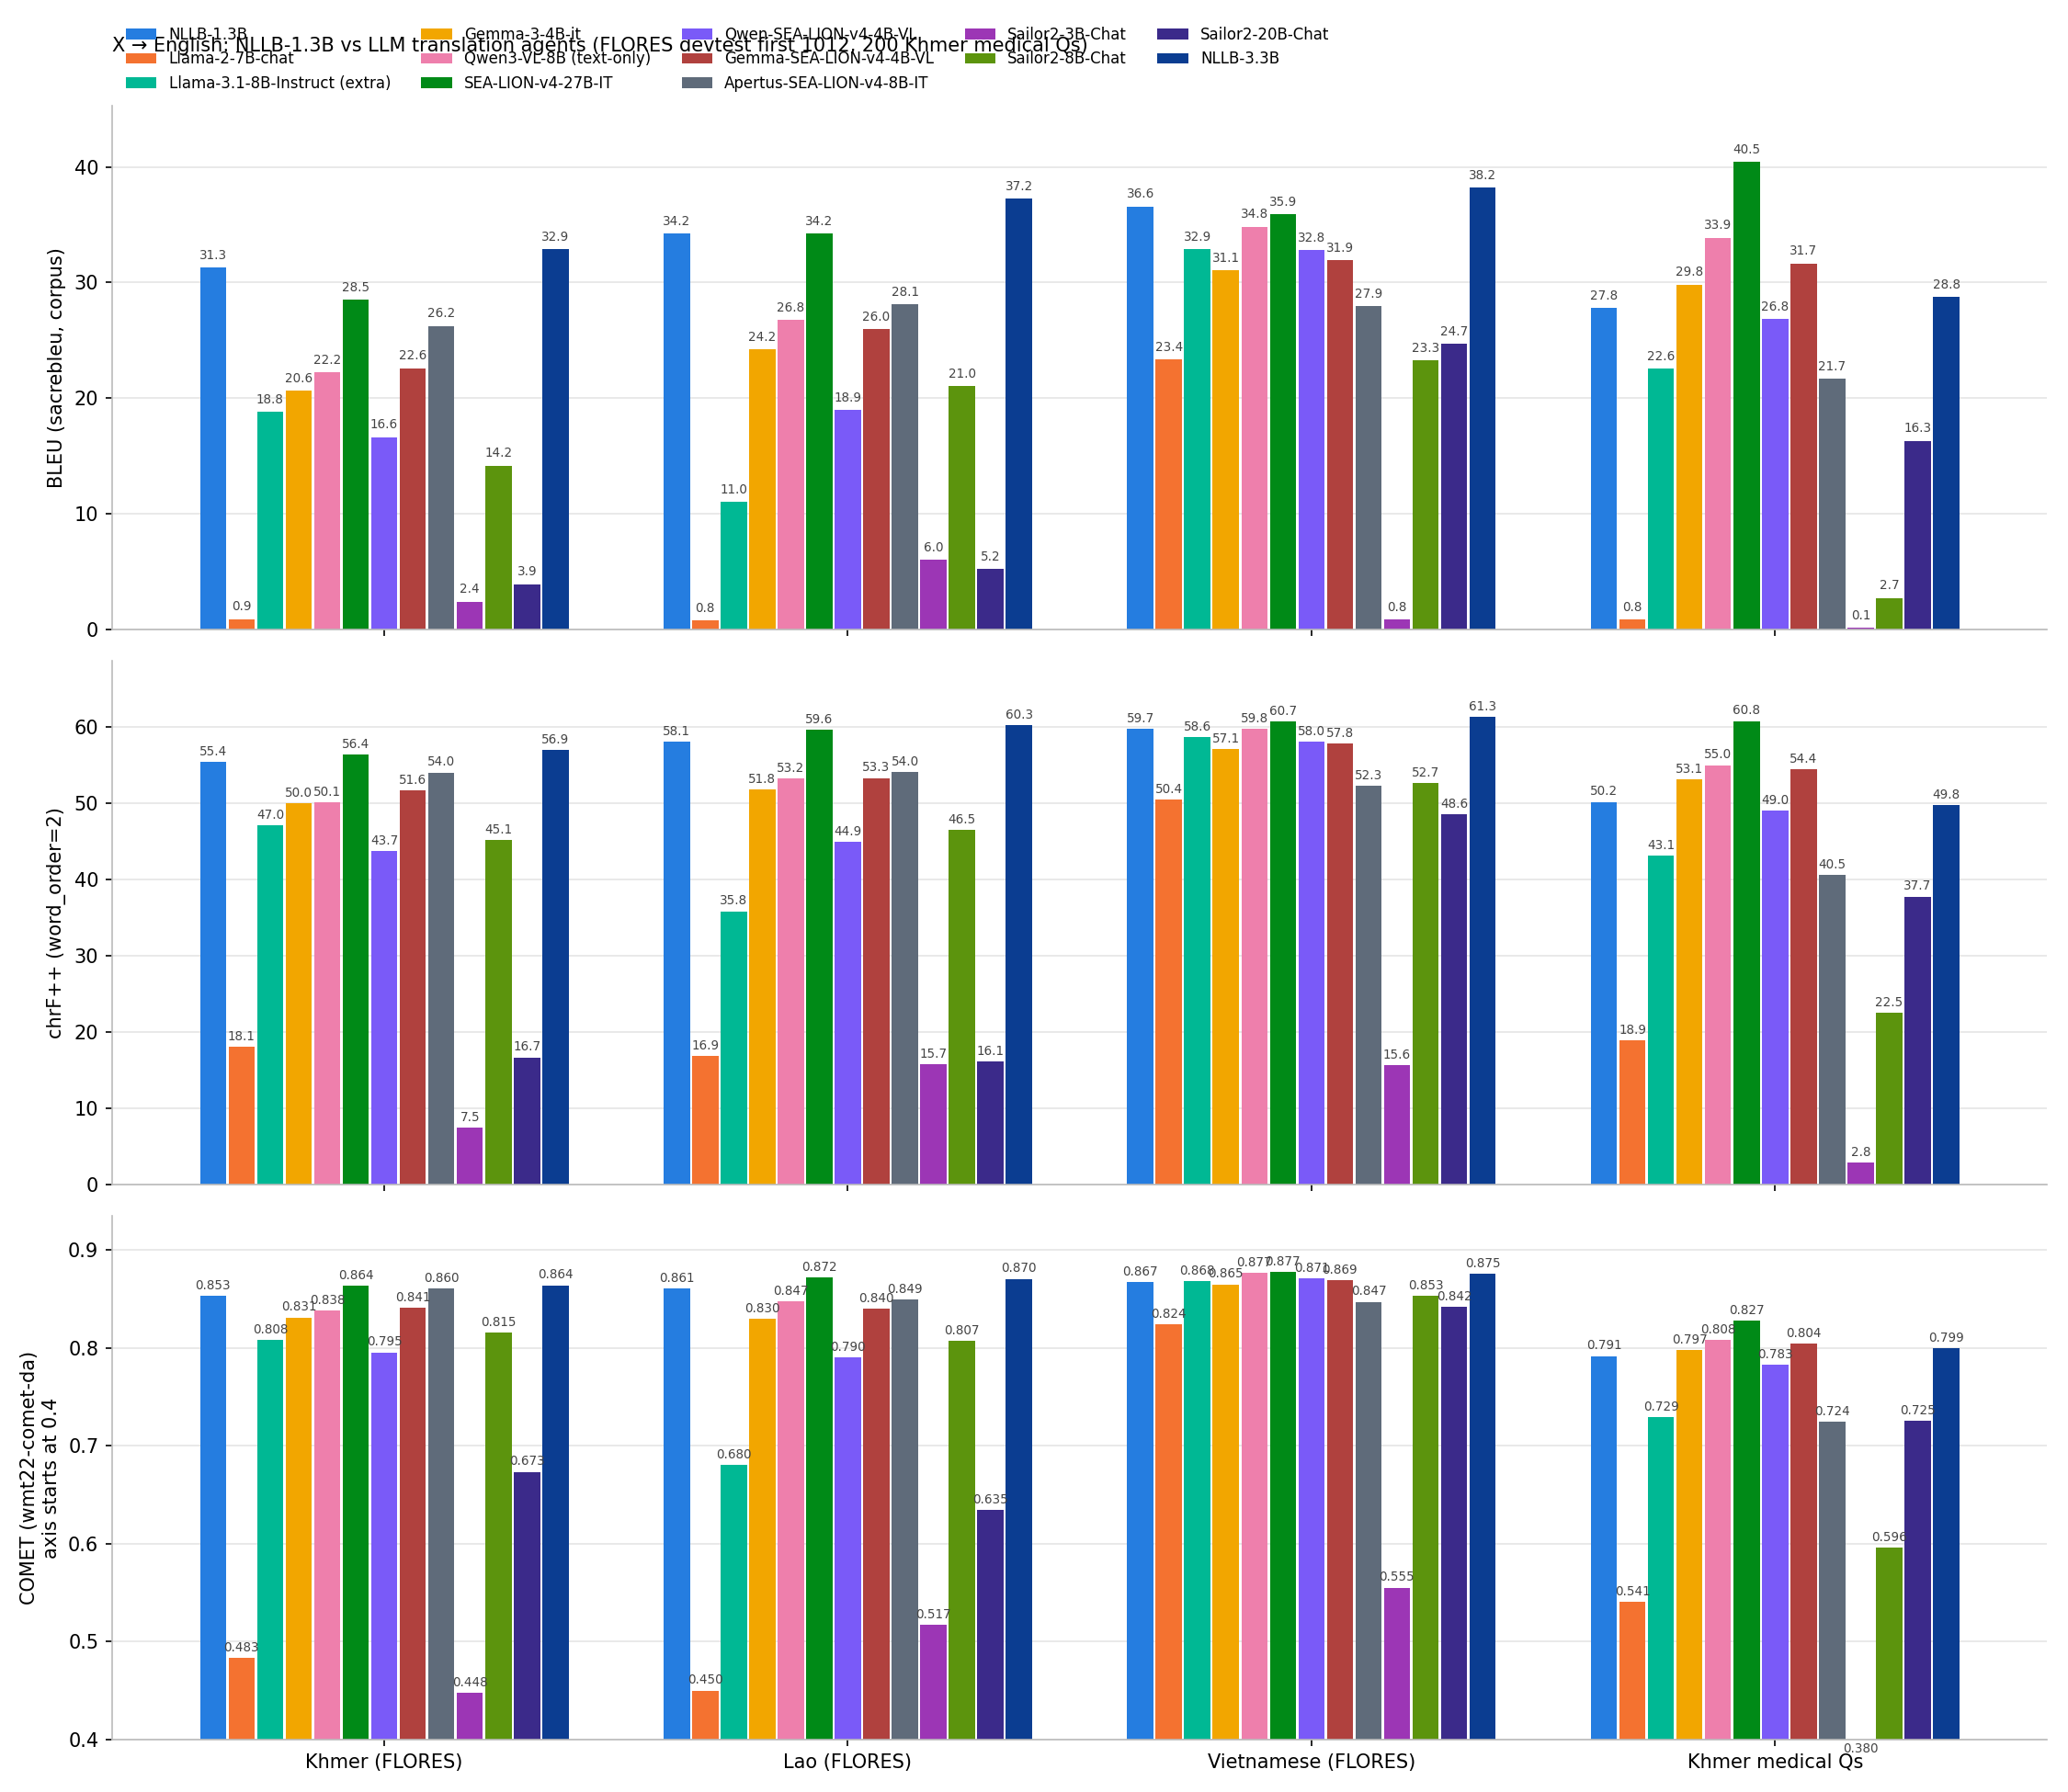

In [7]:
ta = load("translation_agent_results.json")
s = pd.DataFrame(ta["scores"])
cols = ["BLEU", "chrF++", "COMET", "numbers_kept_pct", "loops", "not_english", "sec_per_100"]
for lab in s.label.unique():
    display(Markdown(f"**{lab}**"))
    display(s[s.label == lab].set_index("model")[cols].round(3))
show("translation_agent_bleu.png", 1000)

**Result.**
- **SEA-LION-v4-27B is the best system on every set by chrF++ and COMET**, and the first LLM that matches NLLB on BLEU
  (Lao 34.2 = 34.2). On the real Khmer medical questions it is far ahead: BLEU 40.5 vs 27.8, COMET 0.827 vs 0.792, and it
  keeps all 253 numbers (NLLB: 75%).
- NLLB still has the best BLEU on Khmer and Vietnamese FLORES (BLEU rewards exact wording, COMET rewards meaning).
- Small LLMs: Qwen3-VL-8B is the best of them; Llama-2-7B cannot read Khmer or Lao at all (BLEU < 1, many loops).
- Speed: SEA-LION 5–8 s per 100 FLORES sentences (plus ~4 min to load 52 GB of weights) vs NLLB about 1 s.

## 7. Reverse test, English → X on 100 guideline chunks

**Script:** `reverse_translation.py` · **results:** `out/reverse_mt_results.json`, `out/reverse_mt_report.md`, `out/reverse_mt.png`, raw outputs `out/reverse_mt/`

100 random chunks of the final chunk file (`chunks_256.jsonl`, seed 0: 71 body text, 27 tables, 2 flowcharts; author
lists, image descriptions and chunks over 384 tokens left out), translated to Khmer, Lao and Vietnamese by three systems:

- **NLLB-1.3B** with the fixed pipeline of section 3 (sentence by sentence, table cells one by one, beam 4).
- **Qwen3-VL-8B** and **SEA-LION-v4-27B**: the whole chunk in one prompt, greedy, told to keep numbers, negations,
  drug names in Latin script and the markdown layout.

No human reference exists, so quality is measured two ways:
1. **Checks on the translation** (as in section 3): numbers, negation cue, drug names, units, right script, loops.
   *All checks pass* = a chunk passes every one.
2. **Round trip:** every translation is translated back to English by **two independent back-translators, NLLB and
   SEA-LION**, and compared with the English chunk (chrF++, COMET). Each back-translator tends to favour its own
   model's outputs, so both columns are shown.

all checks pass %  numbers kept %  \
language   system                                                         
Khmer      NLLB-1.3B                                 83            98.6   
           NLLB-3.3B                                 82            98.9   
           Qwen3-VL-8B                               36            70.2   
           SEA-LION-v4-27B-IT                        91            99.6   
           Sailor2-20B-Chat                          70            90.8   
           Qwen-SEA-LION-v4-4B-VL                    22            72.3   
           Gemma-SEA-LION-v4-4B-VL                   46            97.9   
           Apertus-SEA-LION-v4-8B-IT                 28            72.5   
Lao        NLLB-1.3B                                 91            97.2   
           NLLB-3.3B                                 91            99.1   
           Qwen3-VL-8B                               40            76.8   
           SEA-LION-v4-27B-IT                        90            99.6   
           Sailor2-20B-Chat                          56            92.7   
           Qwen-SEA-LION-v4-4B-VL                    14            61.2   
           Gemma-SEA-LION-v4-4B-VL                   29            97.5   
Vietnamese NLLB-1.3B                                 92            98.4   
           NLLB-3.3B                                 90            98.0   
           Qwen3-VL-8B                               92            98.9   
           SEA-LION-v4-27B-IT                        95            99.6   
           Sailor2-20B-Chat                          77            95.2   
           Qwen-SEA-LION-v4-4B-VL                    82            98.8   
           Gemma-SEA-LION-v4-4B-VL                   92            98.8   

                                      extra numbers  negation %  \
language   system                                                 
Khmer      NLLB-1.3B                             39       100.0   
           NLLB-3.3B                             24       100.0   
           Qwen3-VL-8B                           50        76.7   
           SEA-LION-v4-27B-IT                     7       100.0   
           Sailor2-20B-Chat                      28       100.0   
           Qwen-SEA-LION-v4-4B-VL                52        53.3   
           Gemma-SEA-LION-v4-4B-VL                9        50.0   
           Apertus-SEA-LION-v4-8B-IT             45        53.3   
Lao        NLLB-1.3B                              3       100.0   
           NLLB-3.3B                              5       100.0   
           Qwen3-VL-8B                          101        60.0   
           SEA-LION-v4-27B-IT                     3       100.0   
           Sailor2-20B-Chat                      22        83.3   
           Qwen-SEA-LION-v4-4B-VL                83        30.0   
           Gemma-SEA-LION-v4-4B-VL                9        23.3   
Vietnamese NLLB-1.3B                             41       100.0   
           NLLB-3.3B                             39       100.0   
           Qwen3-VL-8B                           25       100.0   
           SEA-LION-v4-27B-IT                     5       100.0   
           Sailor2-20B-Chat                      57       100.0   
           Qwen-SEA-LION-v4-4B-VL                20        96.7   
           Gemma-SEA-LION-v4-4B-VL               16       100.0   

                                      drug names Latin %  units %  \
language   system                                                   
Khmer      NLLB-1.3B                                91.8     90.2   
           NLLB-3.3B                                92.8     86.6   
           Qwen3-VL-8B                              45.4     56.7   
           SEA-LION-v4-27B-IT                       99.0    100.0   
           Sailor2-20B-Chat                         85.6     75.6   
           Qwen-SEA-LION-v4-4B-VL                   56.7     65.9   
           Gemma-SEA-LION-v4-4B-VL                  94.8     92.1   
       

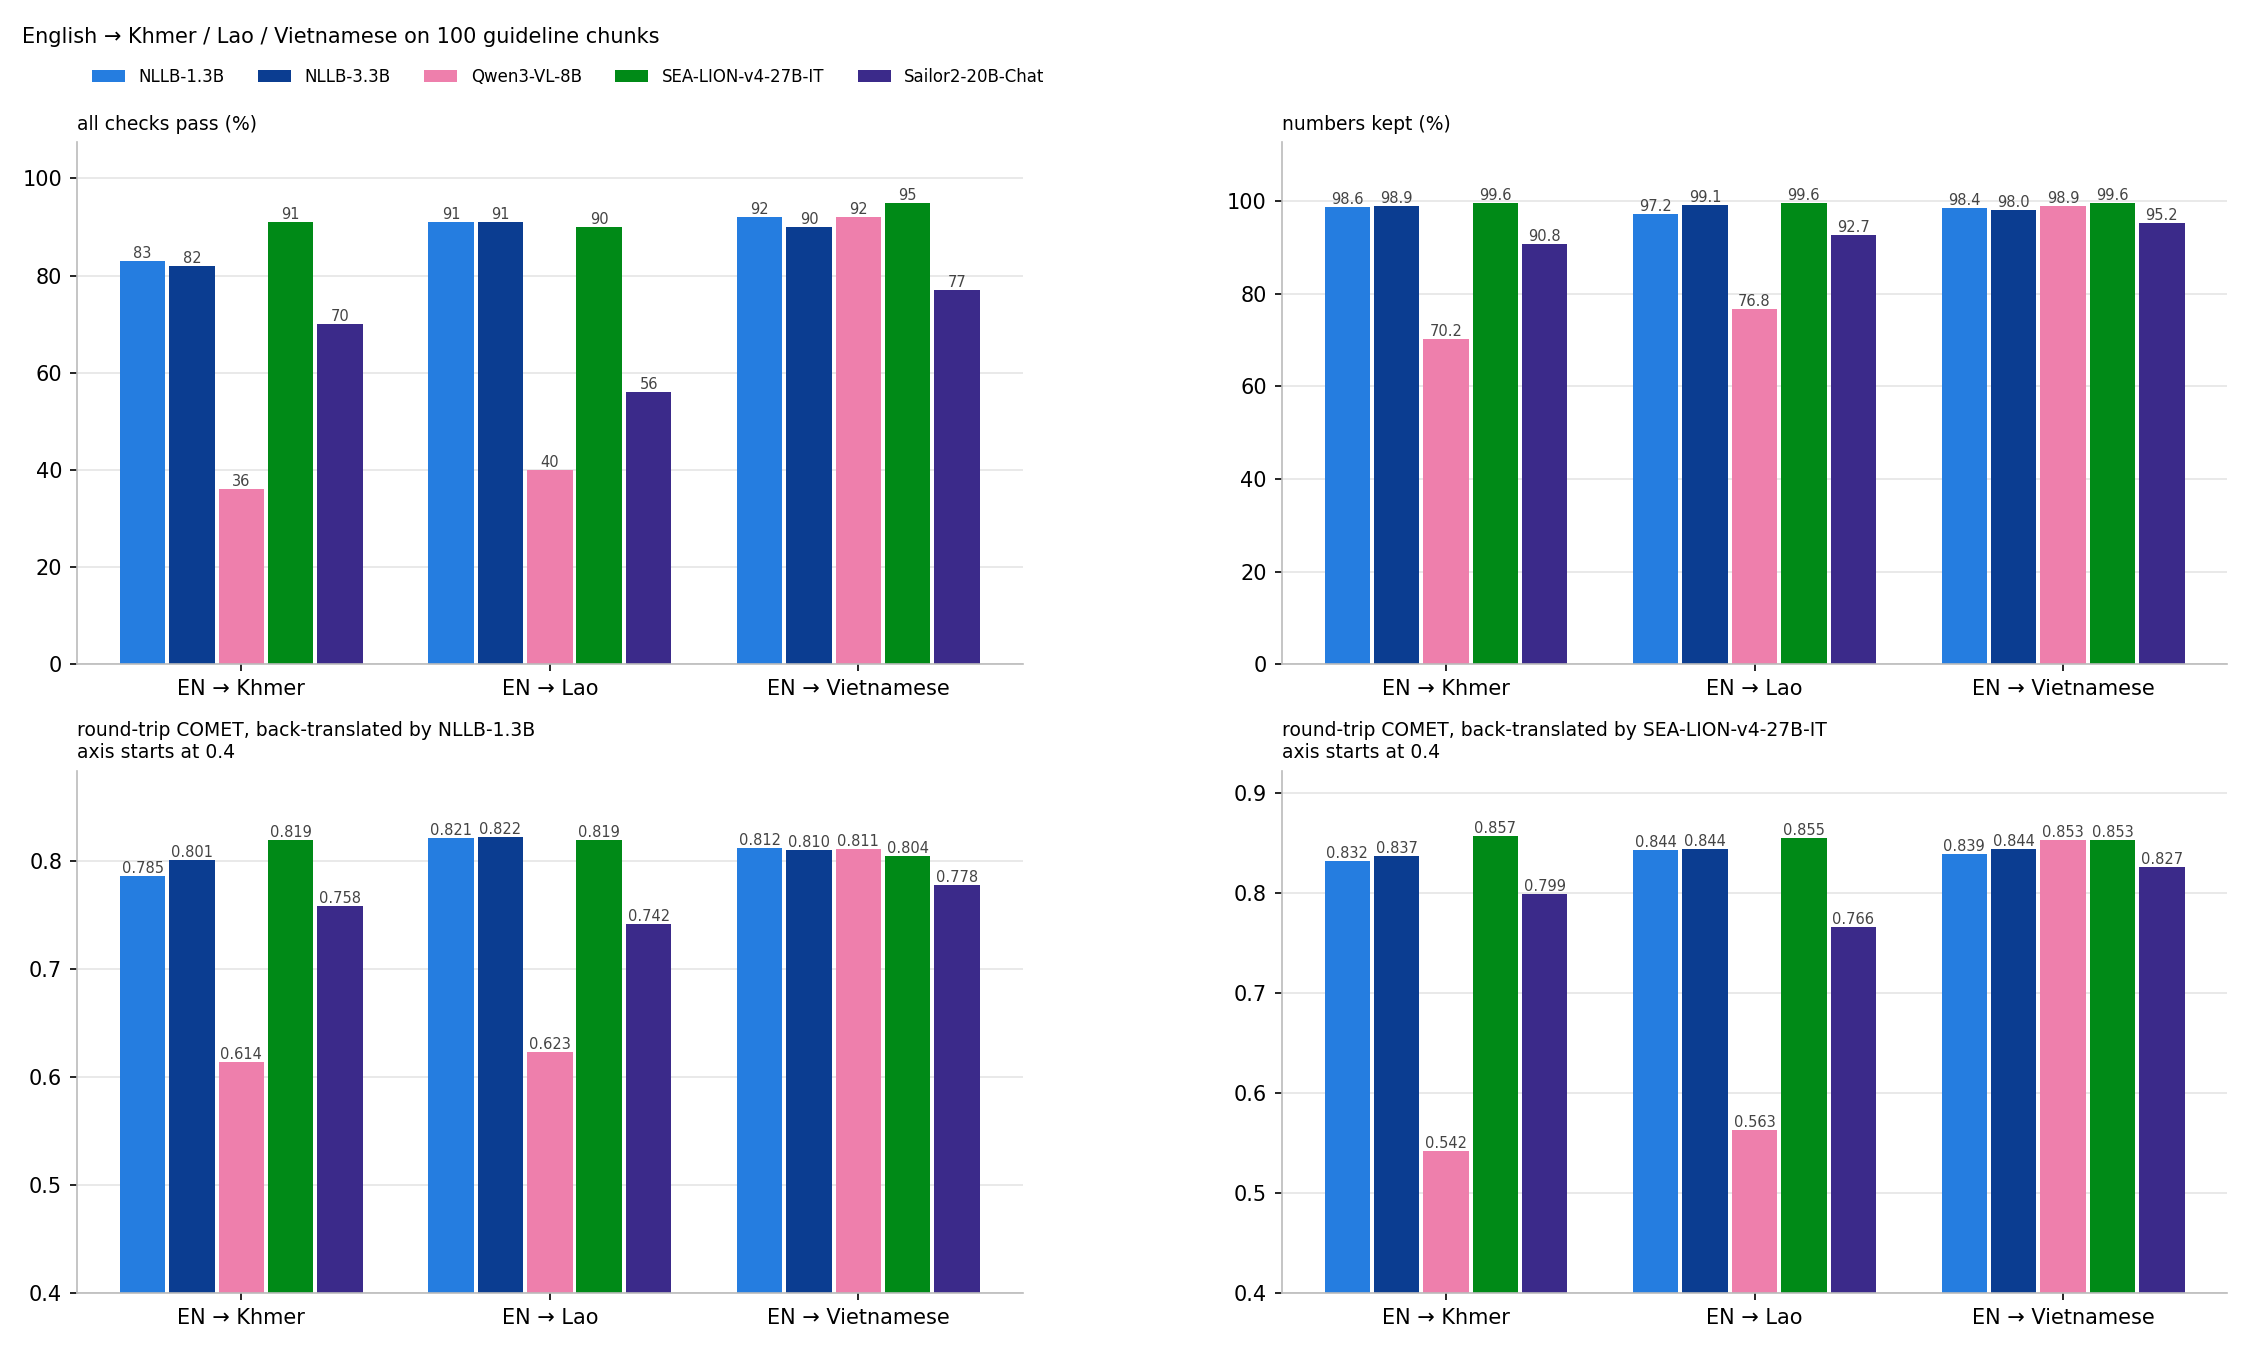

In [8]:
rv = load("reverse_mt_results.json")
r = pd.DataFrame(rv["scores"])
def rtab(df):
    t = pd.DataFrame({
        "system": df.system, "language": df.language,
        "all checks pass %": df.all_ok, "numbers kept %": [pct(a, b) for a, b in zip(df.num_ok, df.num_total)],
        "extra numbers": df.num_spurious, "negation %": [pct(a, b) for a, b in zip(df.neg_ok, df.neg_chunks)],
        "drug names Latin %": [pct(a, b) for a, b in zip(df.drug_latin, df.drug_total)],
        "units %": [pct(a, b) for a, b in zip(df.unit_ok, df.unit_total)],
        "wrong script": df.wrong_script, "loops": df.loops,
        "BT COMET (NLLB)": df["bt_COMET|NLLB-1.3B"], "BT COMET (SEA-LION)": df["bt_COMET|SEA-LION-v4-27B-IT"],
        "BT chrF++ (NLLB)": df["bt_chrF++|NLLB-1.3B"], "BT chrF++ (SEA-LION)": df["bt_chrF++|SEA-LION-v4-27B-IT"],
        "s / chunk": df.sec_per_chunk})
    return t.set_index(["language", "system"])
display(rtab(r))
show("reverse_mt.png", 1000)

In [9]:
# one example: the shortest table chunk, all systems, with the NLLB back-translation so it can be read without the language
D = os.path.join(OUT, "reverse_mt")
rd = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]
ch = rd(os.path.join(D, "chunks.jsonl"))
ex = ch[0]
print("ENGLISH:\n" + ex["text"] + "\n")
slug = lambda m: re.sub(r"[^A-Za-z0-9.]+", "_", m).strip("_")
for lk in ("khm",):
    for sname in ("NLLB-1.3B", "Qwen3-VL-8B", "SEA-LION-v4-27B-IT"):
        fw = rd(os.path.join(D, "fwd", f"{slug(sname)}.{lk}.jsonl"))[ex["id"]]["text"]
        bt = rd(os.path.join(D, "bt", f"{slug(sname)}.{lk}.by_NLLB_1.3B.jsonl"))[ex["id"]]["text"]
        print(f"--- {LANG[lk]}, {sname}\n{fw[:600]}\n  back to English (NLLB): {bt[:600]}\n")

ENGLISH:
| Key points about thrombolytic therapy for PE |  |
|---|---|
| Agent | Alteplase (tPA) |
| Administration | IV infusion |
| Dosing protocol | 100 mg infusion over 2 hours |

--- Khmer, NLLB-1.3B
| ចំណុច សំខាន់ៗ អំពី ការព្យាបាល thrombolytic សម្រាប់ PE |  |
|---|---|
| ភ្នាក់ងារ | Alteplase (tPA) |
| ការគ្រប់គ្រង | ការ ចាក់ វ៉ាក់សាំង ក្នុង ច្រមុះ |
| ក្រមប្រតិបត្តិការចាក់វ៉ាក់សាំង | ការលាបថ្នាំ 100 mg ក្នុងរយៈពេល 2 ម៉ោង |
  back to English (NLLB): | Highlights of thrombolytic treatment for PE |  |
|---|---|
| The agency | Alteplase (tPA) |
| How can we do this? | In fact, it is not uncommon for a person to get a vaccine in his or her nose. |
| The vaccine is administered by the National Institute of Allergy and Infectious Diseases (NIAID). | Taking 100 mg in 2 hours |

--- Khmer, Qwen3-VL-8B
| ចំណុចសំខាន់អំពីការព្យាបាលដោយថ្នាំបំបែកឈាមសម្រាប់ PE |  |
|---|---|
| ថ្នាំ | Alteplase (tPA) |
| ការផ្តល់ថ្នាំ | ការផ្តល់ដោយវ៉ាក់ស៊ីន | 
| ការប្រើប្រាស់ | 100 mg ការផ្តល់ដោយវ៉ាក់ស៊ីនក្នុង

**Result.**
- **SEA-LION** keeps numbers best (99.6% in all three languages), keeps every drug name and unit (Khmer units 100% vs
  NLLB 90%), adds very few spurious numbers, and never loops. All checks pass: Khmer **91** (NLLB 83), Lao 90 (NLLB 91),
  Vietnamese **95** (NLLB 92).
- **NLLB** makes meaning errors no number check can see: in the example above, *"IV infusion"* became roughly
  *"vaccine injection in the nose"*. It also adds more spurious numbers (Khmer 39, Vietnamese 41).
- **Qwen3-VL-8B** degenerates in Khmer and Lao: 55 and 52 of 100 outputs repeat one word until the token limit.
  In Vietnamese it is as good as NLLB.
- SEA-LION's weakness: because it was told to keep medical terms in Latin script, term-heavy chunks stay partly in
  English (wrong-script flag 8 vs NLLB 2), and it left one table (chunk 24) untranslated in Khmer and Lao.
- Lao and Vietnamese are close calls: which of NLLB / SEA-LION wins depends on which back-translator you trust.

## 8. Final comparison: NLLB-1.3B vs Qwen3-VL-8B vs the SEA-LION v4 models, both directions

NLLB-1.3B and NLLB-3.3B (light / dark blue), Qwen3-VL-8B, SEA-LION-v4-27B and Sailor2-20B-Chat (purple), the biggest Sailor2 model, tested in both
directions. Sailor2-3B and 8B are in sections 6 and 9.
A value below a panel's axis start is drawn as a thin stub with its value and ↓. The small SEA-LION v4 models (Qwen-SEA-LION-4B, Gemma-SEA-LION-4B,
Apertus-SEA-LION-8B) are left out; their X → English scores are in section 6.

- **X → English** (section 6): FLORES-200 devtest (1,012 sentences per language) against human English references.
  The Khmer medical questions are left out here (they are in section 6).
- **English → X** (section 7): 100 guideline chunks, no reference; round-trip COMET (mean of the two back-translators) and the safety checks.
  A system with no English → X result yet has no bar there.

The two directions are measured differently, so compare systems *within* a panel, not numbers across panels.

In [10]:
SYS = {"NLLB-1.3B": "NLLB-1.3B", "NLLB-3.3B": "NLLB-3.3B", "Qwen3-VL-8B (text-only)": "Qwen3-VL-8B", "SEA-LION-v4-27B-IT": "SEA-LION-v4-27B-IT",
       "Sailor2-20B-Chat": "Sailor2-20B-Chat"}
x2e = s[s.model.isin(SYS) & (s.set != "medical_khm")].assign(system=lambda d: d.model.map(SYS))
x2e_lang = {"flores_khm": "Khmer", "flores_lao": "Lao", "flores_vie": "Vietnamese"}
x2e = x2e.assign(test=x2e.set.map(x2e_lang))
e2x = r[r.system.isin(SYS.values())].reset_index(drop=True)
e2x = e2x.assign(rt_COMET=(e2x["bt_COMET|NLLB-1.3B"] + e2x["bt_COMET|SEA-LION-v4-27B-IT"]) / 2,   # NaN until back-translated
                 rt_chrF=(e2x["bt_chrF++|NLLB-1.3B"] + e2x["bt_chrF++|SEA-LION-v4-27B-IT"]) / 2,
                 numbers=[pct(a, b) for a, b in zip(e2x.num_ok, e2x.num_total)])

summary = []
for _, q in x2e.iterrows():
    summary.append({"direction": "X → English", "test": q.test, "system": q.system, "COMET": q.COMET,
                    "chrF++": q["chrF++"], "BLEU": q.BLEU, "numbers kept %": q.numbers_kept_pct,
                    "loops": q.loops, "all checks pass %": None})
for _, q in e2x.iterrows():
    summary.append({"direction": "English → X", "test": q.language, "system": q.system, "COMET": round(q.rt_COMET, 4),
                    "chrF++": round(q.rt_chrF, 1), "BLEU": None, "numbers kept %": q.numbers,
                    "loops": q.loops, "all checks pass %": q.all_ok})
summary = pd.DataFrame(summary)
display(Markdown("COMET / chrF++ for English → X are round-trip scores (mean of the NLLB and SEA-LION back-translations)."))
display(summary.set_index(["direction", "test", "system"]))

COMET / chrF++ for English → X are round-trip scores (mean of the NLLB and SEA-LION back-translations).

COMET  chrF++   BLEU  \
direction   test       system                                      
X → English Khmer      NLLB-1.3B           0.8529   55.37  31.30   
            Lao        NLLB-1.3B           0.8607   58.10  34.25   
            Vietnamese NLLB-1.3B           0.8670   59.74  36.58   
            Khmer      NLLB-3.3B           0.8637   56.93  32.90   
            Lao        NLLB-3.3B           0.8704   60.27  37.25   
            Vietnamese NLLB-3.3B           0.8752   61.31  38.23   
            Khmer      Qwen3-VL-8B         0.8376   50.06  22.21   
            Lao        Qwen3-VL-8B         0.8473   53.25  26.75   
            Vietnamese Qwen3-VL-8B         0.8767   59.75  34.84   
            Khmer      SEA-LION-v4-27B-IT  0.8635   56.39  28.49   
            Lao        SEA-LION-v4-27B-IT  0.8717   59.61  34.25   
            Vietnamese SEA-LION-v4-27B-IT  0.8772   60.72  35.93   
            Khmer      Sailor2-20B-Chat    0.6733   16.66   3.89   
            Lao        Sailor2-20B-Chat    0.6346   16.14   5.20   
            Vietnamese Sailor2-20B-Chat    0.8420   48.58  24.70   
English → X Khmer      NLLB-1.3B           0.8089   60.70    NaN   
                       NLLB-3.3B           0.8189   64.50    NaN   
                       Qwen3-VL-8B         0.5776   27.60    NaN   
                       SEA-LION-v4-27B-IT  0.8383   69.50    NaN   
                       Sailor2-20B-Chat    0.7782   50.20    NaN   
            Lao        NLLB-1.3B           0.8325   69.90    NaN   
                       NLLB-3.3B           0.8334   70.30    NaN   
                       Qwen3-VL-8B         0.5930   28.20    NaN   
                       SEA-LION-v4-27B-IT  0.8368   68.90    NaN   
                       Sailor2-20B-Chat    0.7539   48.80    NaN   
            Vietnamese NLLB-1.3B           0.8254   71.50    NaN   
                       NLLB-3.3B           0.8270   71.30    NaN   
                       Qwen3-VL-8B         0.8319   66.50    NaN   
                       SEA-LION-v4-27B-IT  0.8285   70.00    NaN   
                       Sailor2-20B-Chat    0.8020   59.00    NaN   

                                           numbers kept %  loops  \
direction   test       system                                      
X → English Khmer      NLLB-1.3B                     93.3      0   
            Lao        NLLB-1.3B                     95.9      0   
            Vietnamese NLLB-1.3B                     89.9      0   
            Khmer      NLLB-3.3B                     94.2      1   
            Lao        NLLB-3.3B                     95.0      1   
            Vietnamese NLLB-3.3B                     90.7      0   
            Khmer      Qwen3-VL-8B                   93.3      0   
            Lao        Qwen3-VL-8B                   98.3      0   
            Vietnamese Qwen3-VL-8B                   93.4      0   
            Khmer      SEA-LION-v4-27B-IT            99.4      0   
            Lao        SEA-LION-v4-27B-IT            99.7      0   
            Vietnamese SEA-LION-v4-27B-IT            96.6      0   
            Khmer      Sailor2-20B-Chat              95.8      0   
            Lao        Sailor2-20B-Chat              99.2      6   
            Vietnamese Sailor2-20B-Chat              95.0      0   
English → X Khmer      NLLB-1.3B                     98.6      0   
                       NLLB-3.3B                     98.9      0   
                       Qwen3-VL-8B                   70.2     55   
                       SEA-LION-v4-27B-IT            99.6      0   
                       Sailor2-20B-Chat              90.8      0   
            Lao        NLLB-1.3B                     97.2      0   
                       NLLB-3.3B                     99.1      0   
                       Qwen3-VL-8B                   76.8     52   
                       SEA-LION-v4-27B-IT            99.6      0   
                       Sailor2-20B-Chat              92.7      0   
            Vietnamese NLLB-1.3

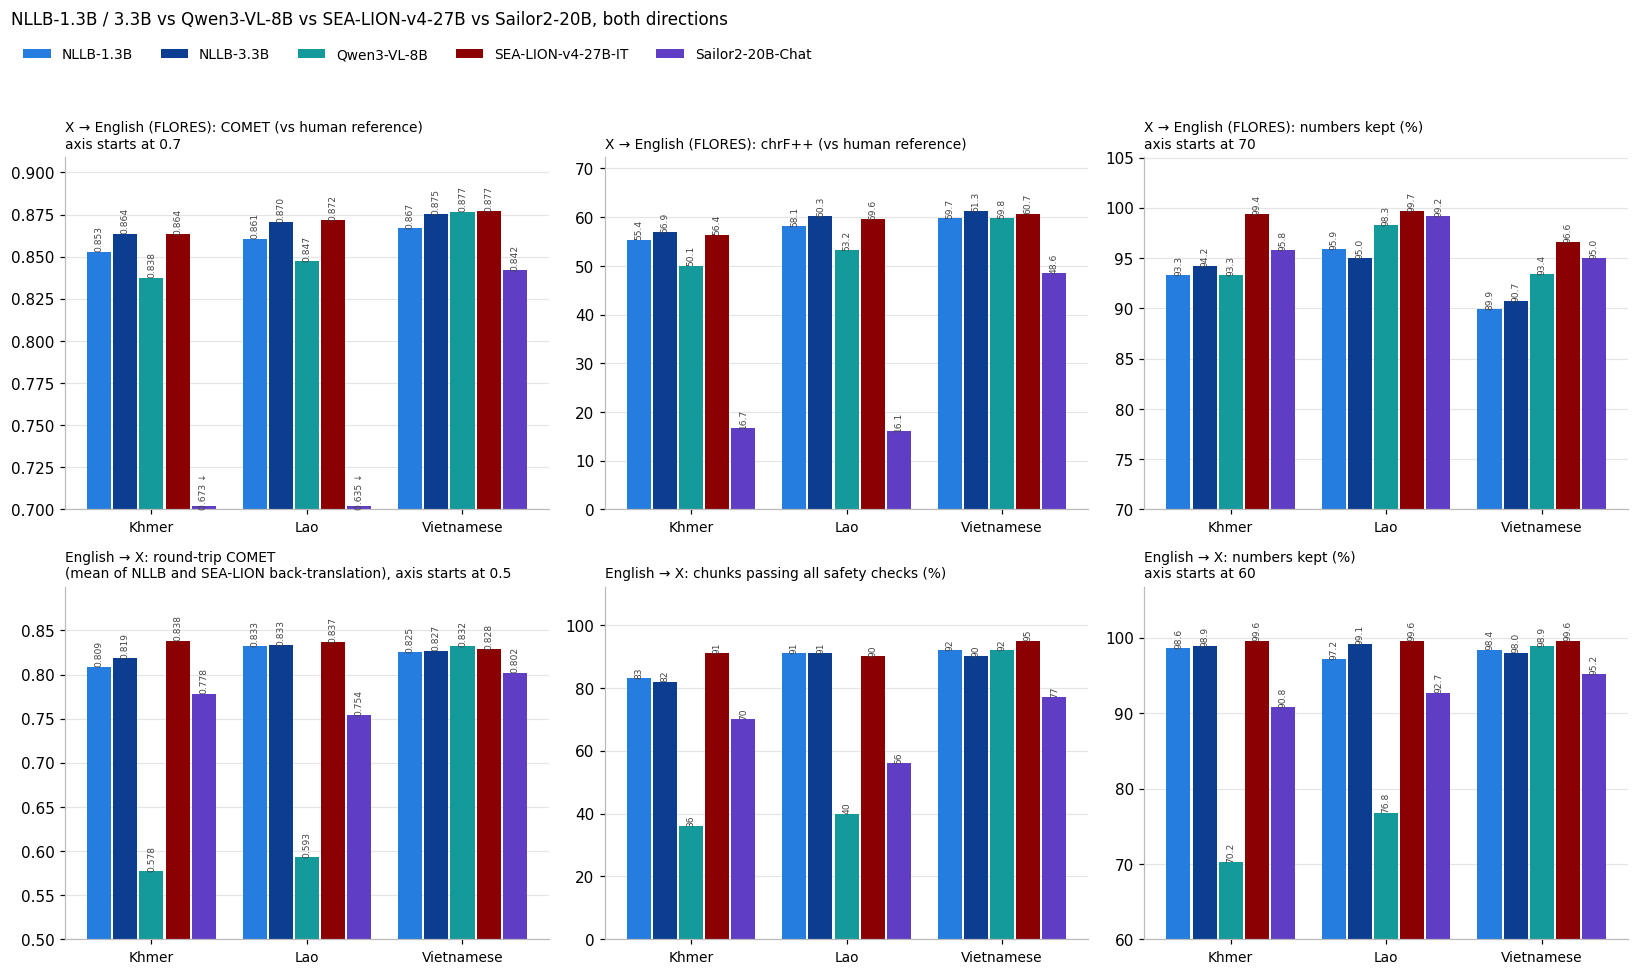

In [11]:
systems = list(COL8)
def bars(ax, groups, getter, title, lo=0, fmt="{:.1f}"):
    w = 0.84 / len(systems); top = lo
    for j, sname in enumerate(systems):
        vals = [getter(sname, g) for g in groups]
        top = max([top] + [v for v in vals if v is not None])
        xs = [i + (j - (len(systems) - 1) / 2) * w for i in range(len(groups))]
        keep = [(x, v) for x, v in zip(xs, vals) if v is not None]   # no bar where a system has no result
        stub = (top - lo) * 0.01 if top > lo else 0.001
        b = ax.bar([x for x, _ in keep], [max(v - lo, stub) for _, v in keep], w * 0.92, bottom=lo, color=COL8[sname],
                   label=sname, zorder=2)                            # a value below the axis start: thin stub, real value printed
        for bb, (_, v) in zip(b, keep):
            ax.text(bb.get_x() + bb.get_width() / 2, max(v, lo), fmt.format(v) + (" ↓" if v < lo else ""), ha="center",
                    va="bottom", fontsize=6, color="#444", rotation=90)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups, fontsize=9)
    ax.set_ylim(lo, top + (top - lo) * 0.18); ax.set_title(title, loc="left", fontsize=9)
    ax.grid(axis="y", color="#e5e5e5", zorder=0)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color("#bbb"); ax.spines["bottom"].set_color("#bbb")

def cell(df, key, sn, g, col):
    v = df[(df.system == sn) & (df[key] == g)][col]
    return None if v.empty or pd.isna(v.iloc[0]) else float(v.iloc[0])

lg = ["Khmer", "Lao", "Vietnamese"]
xv = lambda col: (lambda sn, g: cell(x2e, "test", sn, g, col))
ev = lambda col: (lambda sn, g: cell(e2x, "language", sn, g, col))

fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=110)
bars(axes[0, 0], lg, xv("COMET"), "X → English (FLORES): COMET (vs human reference)\naxis starts at 0.7", lo=0.7, fmt="{:.3f}")
bars(axes[0, 1], lg, xv("chrF++"), "X → English (FLORES): chrF++ (vs human reference)")
bars(axes[0, 2], lg, xv("numbers_kept_pct"), "X → English (FLORES): numbers kept (%)\naxis starts at 70", lo=70)
bars(axes[1, 0], lg, ev("rt_COMET"), "English → X: round-trip COMET\n(mean of NLLB and SEA-LION back-translation), axis starts at 0.5", lo=0.5, fmt="{:.3f}")
bars(axes[1, 1], lg, ev("all_ok"), "English → X: chunks passing all safety checks (%)", fmt="{:.0f}")
bars(axes[1, 2], lg, ev("numbers"), "English → X: numbers kept (%)\naxis starts at 60", lo=60)
fig.legend(*axes[0, 0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=5, loc="upper left", bbox_to_anchor=(0.01, 0.955))
fig.suptitle("NLLB-1.3B / 3.3B vs Qwen3-VL-8B vs SEA-LION-v4-27B vs Sailor2-20B, both directions",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(OUT, "translation_final_comparison.png"))
plt.show()

In [12]:
# who wins each test (COMET), and how often
win = summary.loc[summary.groupby(["direction", "test"])["COMET"].idxmax(), ["direction", "test", "system", "COMET"]]
display(win.set_index(["direction", "test"]))
speed = pd.DataFrame({
    "X → English, s / 100 FLORES sentences": x2e[x2e.set == "flores_khm"].set_index("system").sec_per_100,
    "English → Khmer, s / chunk": e2x[e2x.lang == "khm"].set_index("system").sec_per_chunk})
display(speed)

system   COMET
direction   test                                  
English → X Khmer       SEA-LION-v4-27B-IT  0.8383
            Lao         SEA-LION-v4-27B-IT  0.8368
            Vietnamese         Qwen3-VL-8B  0.8319
X → English Khmer                NLLB-3.3B  0.8637
            Lao         SEA-LION-v4-27B-IT  0.8717
            Vietnamese  SEA-LION-v4-27B-IT  0.8772

,"X → English, s / 100 FLORES sentences","English → Khmer, s / chunk"
system,,
NLLB-1.3B,NaN,0.91
NLLB-3.3B,NaN,0.82
Qwen3-VL-8B,5.70,4.27
SEA-LION-v4-27B-IT,7.12,2.25
Sailor2-20B-Chat,23.44,2.70


### Conclusions

| | X → English (questions, Khmer pages) | English → X (guideline answers) |
|---|---|---|
| **SEA-LION-v4-27B** | **Best overall.** Highest COMET and chrF++ on all four sets; on the real Khmer medical questions far ahead (COMET 0.827 vs 0.792, BLEU 40.5 vs 27.8) and keeps every number. | **Best on Khmer; on Lao and Vietnamese about tied** (round-trip COMET within 0.01 of the others; most chunks passing all checks in Khmer and Vietnamese). Keeps numbers (99.6%), drug names and units best and never loops. Weak spot: term-heavy chunks stay partly in English; one table left untranslated. |
| **NLLB-1.3B** | Good and fast; best BLEU on Khmer and Vietnamese FLORES, but behind on meaning (COMET) and on medical questions; drops numbers on the medical questions (75% kept). Hallucinates on short or broken Khmer (section 5). | Solid after the fixes of section 3 and very fast (< 1 s per chunk), but makes silent meaning errors ("IV infusion" → "vaccine in the nose") and adds spurious numbers. |
| **Qwen3-VL-8B** | Best of the small LLMs, below NLLB on Khmer and Lao FLORES, above it on medical questions. | **Not usable for Khmer and Lao** (more than half of the outputs loop); as good as NLLB for Vietnamese. |

**Recommendation.** Use SEA-LION-v4-27B for both directions where a GPU with ~60 GB is available. Keep NLLB-1.3B (with
the fixed pipeline and the chrF gate) as the fast fallback. Do not use Qwen3-VL-8B for Khmer or Lao.

**Caveats.**
- English → X has no human reference; round-trip scores can hide errors that a back-translator "repairs", and each
  back-translator favours its own model. A native-speaker check of a sample is still needed before showing
  translated guideline text to patients or clinicians.
- The LLMs were told to keep drug names in Latin script; NLLB was not told anything (it cannot be prompted).
- One run each, greedy decoding, no repetition penalty for the LLMs (NLLB gets one loop retry).

## 9. Small vs mid-size vs big models

The LLMs we have results for, grouped by size: **small** (3–4B), **mid** (8B), **big** (20–27B). NLLB-1.3B and the
Llama models are left out (their scores are in sections 1 and 6).

- **Top row, X → English**: FLORES-200 devtest, 1,012 sentences per language, COMET against the human English (section 6).
- **Bottom row, English → X**: 100 guideline chunks, share of chunks passing all safety checks (section 7). Only the models
  that were run in this direction have a bar; Apertus-SEA-LION-8B only has Khmer.

Dashed lines are the mean of each size group. \* Sailor2-3B ran to the length limit on every sentence (most likely a
stop-token setup problem, confirmed later and fixed for new runs: Sailor2 ends a reply with `<|im_end|>`, but its
generation stop token is `<|endoftext|>`), so its scores are not its real quality. Sailor2-20B was run with the fix; it
often answers in Khmer/Lao instead of translating into English (Lao: 475 of 1,012 sentences), which lowers its X → English scores. The Khmer medical questions are left
out, as in section 8.

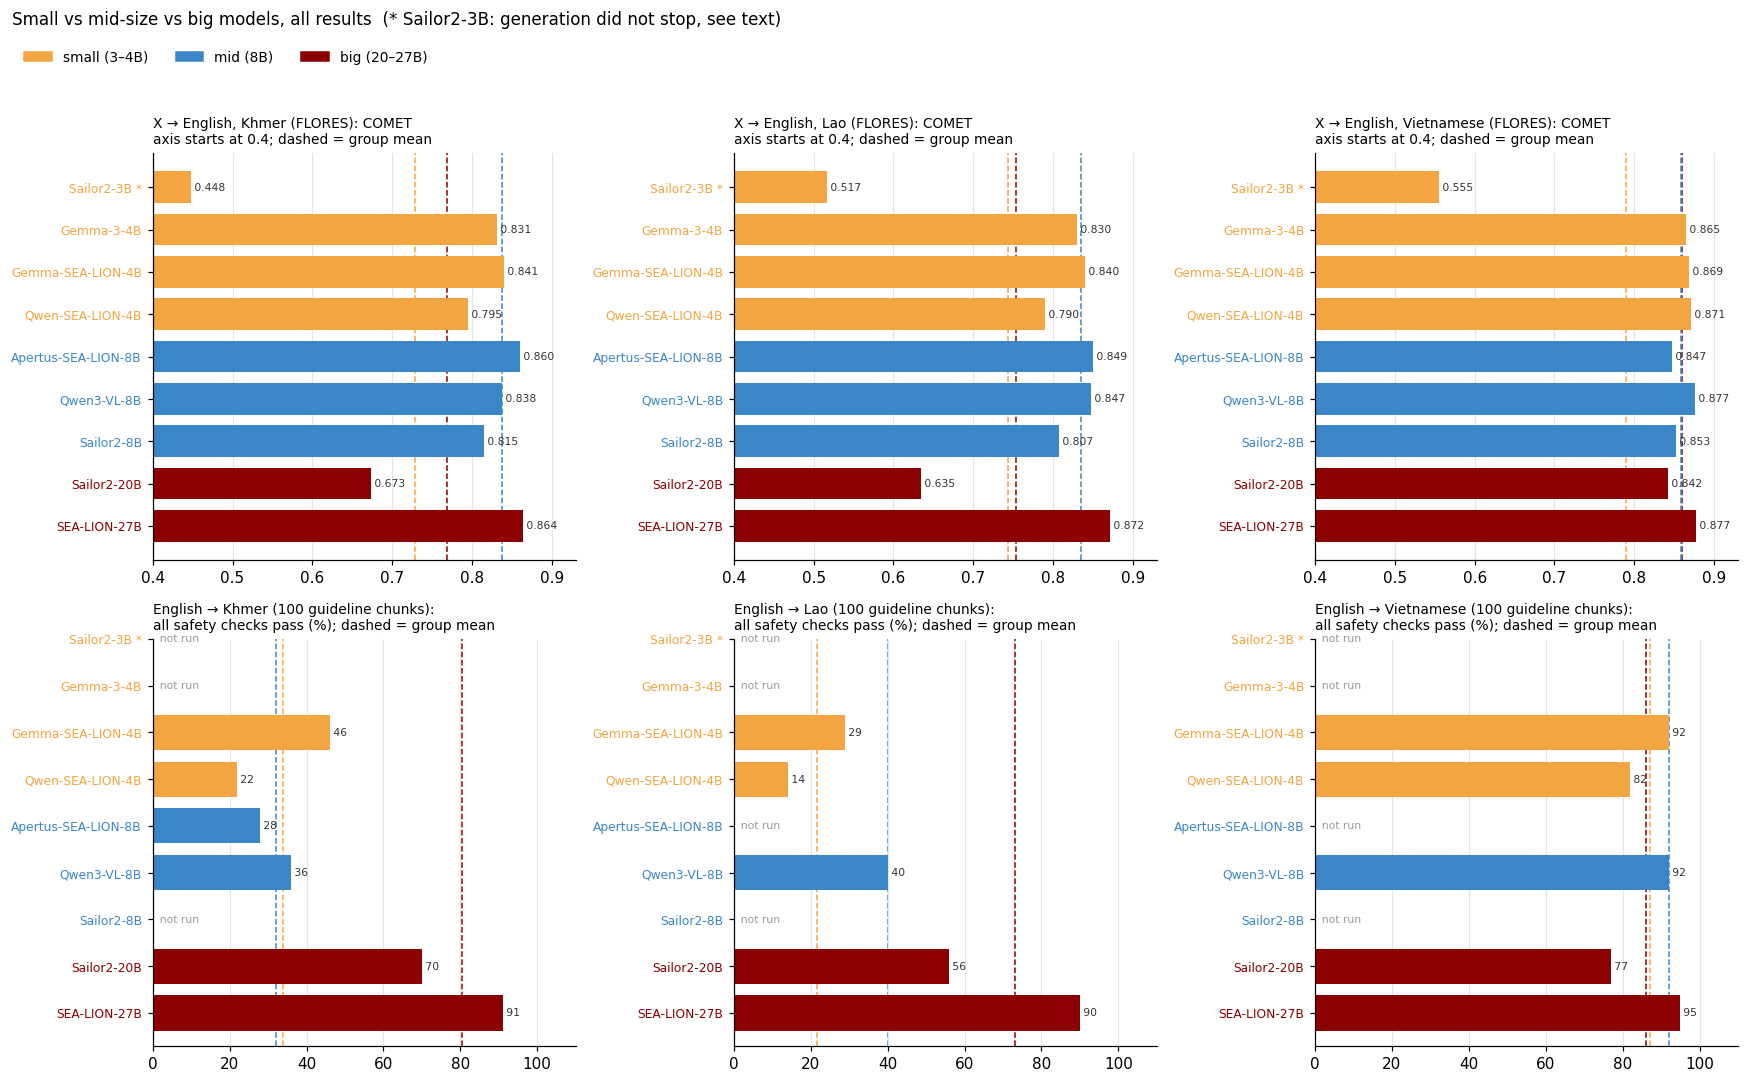

**X → English COMET by size group** (mean and best over the models in the group, FLORES)

mean                      max                   count               
lang   Khmer    Lao Vietnamese  Khmer    Lao Vietnamese Khmer Lao Vietnamese
group                                                                       
small  0.729  0.744      0.790  0.841  0.840      0.871     4   4          4
mid    0.838  0.835      0.859  0.860  0.849      0.877     3   3          3
big    0.768  0.753      0.860  0.864  0.872      0.877     2   2          2

In [13]:
SIZE = {  # result name -> (label, size group, billions of parameters)
    "Sailor2-3B-Chat": ("Sailor2-3B *", "small", 3),
    "Gemma-3-4B-it": ("Gemma-3-4B", "small", 4),
    "Qwen-SEA-LION-v4-4B-VL": ("Qwen-SEA-LION-4B", "small", 4),
    "Gemma-SEA-LION-v4-4B-VL": ("Gemma-SEA-LION-4B", "small", 4),
    "Qwen3-VL-8B (text-only)": ("Qwen3-VL-8B", "mid", 8), "Qwen3-VL-8B": ("Qwen3-VL-8B", "mid", 8),
    "Apertus-SEA-LION-v4-8B-IT": ("Apertus-SEA-LION-8B", "mid", 8),
    "Sailor2-8B-Chat": ("Sailor2-8B", "mid", 8),
    "Sailor2-20B-Chat": ("Sailor2-20B", "big", 20),
    "SEA-LION-v4-27B-IT": ("SEA-LION-27B", "big", 27),
}
GROUP_COL = {"small": "#f2a541", "mid": "#3a86c8", "big": "#8b0000"}
GROUP_NAME = {"small": "small (3–4B)", "mid": "mid (8B)", "big": "big (20–27B)"}
ORDER = ["small", "mid", "big"]
LANG3 = ["Khmer", "Lao", "Vietnamese"]

def size_rows(df, model_col, lang_col, lang_map, val_col):
    out = []
    for _, q in df.iterrows():
        if q[model_col] in SIZE and q[lang_col] in lang_map:
            lab, g, b = SIZE[q[model_col]]
            out.append({"model": lab, "group": g, "b": b, "lang": lang_map[q[lang_col]], "v": q[val_col]})
    return pd.DataFrame(out)

x2e_all = size_rows(s, "model", "set", {"flores_khm": "Khmer", "flores_lao": "Lao", "flores_vie": "Vietnamese"}, "COMET")
e2x_all = size_rows(r.assign(all_ok_pct=100 * r.all_ok / r.n), "system", "lang",
                    {"khm": "Khmer", "lao": "Lao", "vie": "Vietnamese"}, "all_ok_pct")
mods = x2e_all.drop_duplicates("model").sort_values(["b", "model"], key=lambda c: c if c.name == "b" else c.str.lower())
mods = mods.assign(o=mods.group.map(ORDER.index)).sort_values(["o", "b", "model"])
mlist, mgroup = list(mods.model), dict(zip(mods.model, mods.group))

def hbars(ax, df, lang, title, lo, fmt):
    d = df[df.lang == lang].set_index("model")
    ys = list(range(len(mlist)))[::-1]
    for y, m in zip(ys, mlist):
        if m not in d.index:
            ax.text(lo, y, "  not run", va="center", fontsize=7, color="#999")
            continue
        v = d.loc[m, "v"]
        ax.barh(y, max(v - lo, 0), left=lo, height=0.75, color=GROUP_COL[mgroup[m]], zorder=2)
        ax.text(max(v, lo), y, " " + fmt.format(v) + (" (below axis)" if v < lo else ""), va="center", fontsize=7, color="#333")
    for g, v in df[df.lang == lang].groupby("group").v.mean().items():   # group means
        ax.axvline(v, color=GROUP_COL[g], ls="--", lw=1, zorder=1)
    ax.set_yticks(ys); ax.set_yticklabels(mlist, fontsize=8)
    for t, m in zip(ax.get_yticklabels(), mlist):
        t.set_color(GROUP_COL[mgroup[m]])
    ax.set_title(title, loc="left", fontsize=9); ax.grid(axis="x", color="#e5e5e5", zorder=0)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

fig, axes = plt.subplots(2, 3, figsize=(16, 10), dpi=110)
for j, lang in enumerate(LANG3):
    hbars(axes[0, j], x2e_all, lang, f"X → English, {lang} (FLORES): COMET\naxis starts at 0.4; dashed = group mean", 0.4, "{:.3f}")
    axes[0, j].set_xlim(0.4, 0.93)
    hbars(axes[1, j], e2x_all, lang, f"English → {lang} (100 guideline chunks):\nall safety checks pass (%); dashed = group mean", 0, "{:.0f}")
    axes[1, j].set_xlim(0, 110)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=GROUP_COL[g], label=GROUP_NAME[g]) for g in ORDER], frameon=False, ncol=3,
           loc="upper left", bbox_to_anchor=(0.01, 0.955), fontsize=9)
fig.suptitle("Small vs mid-size vs big models, all results  (* Sailor2-3B: generation did not stop, see text)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(os.path.join(OUT, "translation_by_size.png"))
plt.show()

summ = x2e_all.groupby(["group", "lang"]).v.agg(["mean", "max", "count"]).round(3).unstack("lang").reindex(ORDER)
display(Markdown("**X → English COMET by size group** (mean and best over the models in the group, FLORES)"))
display(summ)
